# 01 · Preprocessing — Gaiti 2019 CLL (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, resolve the manifold's transcriptional compartments, and fix a single house
orientation for every downstream UMAP. Gaiti et al. (2019) profiled chronic lymphocytic leukemia
(CLL) B cells (CD19+) from **5 patients** across paired pre-treatment / post-ibrutinib timepoints
by **SmartSeq2** (plate-based, ~96 cells per plate). All profiled cells are the malignant CLL
clone (the loader labels them `Malignant`). Whether the gastrulation / somitogenesis / neural-crest
developmental axis resolves into competing arms (Puram) or collapses onto one gradient (Kürten /
Olalekan / Galen) is **derived in 02–03 from the signature geography**, not assumed here. Every
tunable choice is *derived from this dataset*, not inherited. Deliverable: `processed.h5ad`,
`samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gaiti2019_Hematologic | category: Hematologic


### Load malignant compartment
Gaiti et al. profiled FACS-sorted CD19+ CLL cells — every profiled cell is the malignant clone, so
the loader's default `Malignant` label applies to all. SmartSeq2 expression is supplied as **TPM**;
the loader passes TPM through and `log1p`-transforms it.

In [3]:
adata = load_CCCA_adata(pth_in)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Gaiti2019_Hematologic
Done.
malignant: (720, 55764) | samples: 8 | patients: 5
expression: X max 10.49 (log1p of TPM)


### Sample thresholding — plate-based, derived not inherited
This is **plate-based SmartSeq2**: per-sample counts are near-constant at one 96-well plate each
(seven samples at 96 cells, one half-plate at 48) — **not** the smoothly-varying droplet-depth
distribution the anchor's ≥100-cell floor assumes. That inherited floor (a 10x constant) would drop
**all 8 samples** here — an assumption violation (C3/C4). The only cliff in the sorted counts is the
full-plate→half-plate step (96→48, ratio 2.0, a dominant multiplicative gap), so we cut at its
geometric mean (~67): keep the seven full plates, drop the single 48-cell half-plate so every
retained sample contributes a comparable ~96-cell draw to the Harmony integration.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]
FLOOR = 100
dominant = (srt[0] / srt[1] >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover/plate cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'top gap {int(vals[gap])}->{int(vals[gap+1])} ratio {srt[0]:.2f}; top/second {srt[0]/srt[1]:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant plate cliff -> geometric-mean threshold = {thresh} (floor {FLOOR} would drop ALL plate-based samples)')
else:
    thresh = FLOOR
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'CLL03_pre_treatment': np.int64(96), 'CLL03_post_ibrutinib': np.int64(96), 'CLL04_pre_treatment': np.int64(96), 'CLL04_post_ibrutinib': np.int64(96), 'CLL05_pre_treatment': np.int64(96), 'CLL05_post_ibrutinib': np.int64(96), 'CLL12_pre_treatment': np.int64(96), 'CLL11_post_ibrutinib': np.int64(48)}
gap ratios: ['96->96:1.00', '96->96:1.00', '96->96:1.00', '96->96:1.00', '96->96:1.00', '96->96:1.00', '96->48:2.00']
top gap 96->48 ratio 2.00; top/second 2.00; dominant cliff = True
dominant plate cliff -> geometric-mean threshold = 67 (floor 100 would drop ALL plate-based samples)
kept 7/8 samples (min per-sample 96) -> 672 cells


### Overdispersion, PCA, Harmony integration, embedding
CLL is a clonal malignancy with low transcriptional heterogeneity, so the protocol's
overdispersion test (`find_overdispersed`) recovers a compact gene set; PCA components are capped
below that count. `theta` is chosen by a same-sample-neighbour-fraction / iLISI sweep: mixing
improves sharply to theta=5 and then flattens (theta=10 within noise), so theta=5 sits on the
mixing plateau — strong enough to remove the pre/post-treatment and patient batch structure without
over-integrating. PC count (20) and UMAP spread (1.3) follow the comparable-scale precedents.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
nhvg = int(adata.var.highly_variable.sum())
n_pca = min(50, nhvg - 1, adata.shape[0] - 1)
print('overdispersed genes:', nhvg, '| PCA n_comps:', n_pca, '(capped below overdispersed count — clonal CLL)')
sc.pp.pca(adata, n_comps=n_pca)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def _ilisi(rep, labels, k=90):
    nn = _NN(n_neighbors=k+1).fit(rep); idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
sweep = {}; ilsw = {}
for th in [1, 2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
    ilsw[th]  = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print('same-sample nbr frac | pre %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
print(f'iLISI (of {nsamp}) | pre %.2f' % il_pre, '| sweep', {k: round(v,2) for k,v in ilsw.items()})
theta = 5
print('selected theta =', theta, '(mixing plateaus by theta=5; theta=10 within noise)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 45 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 45 | PCA n_comps: 44 (capped below overdispersed count — clonal CLL)
same-sample nbr frac | pre 0.656 | sweep {1: 0.448, 2: 0.317, 5: 0.213, 10: 0.188}
iLISI (of 7) | pre 1.99 | sweep {1: np.float64(2.44), 2: np.float64(4.2), 5: np.float64(5.53), 10: np.float64(5.57)}
selected theta = 5 (mixing plateaus by theta=5; theta=10 within noise)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous termini. The manifold here is already a single connected component (no islands).

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Compartment split + cell-cycle check (data-driven)
Low-resolution Leiden (res=0.15) resolves the manifold's lobes; the CLL malignant manifold is a
**single low-cycling body** (>98% not-cycling, one Leiden lobe) — there is no separable
proliferative lobe, so the cell-cycle-confound scoping question (Kürten / Lin) does not arise. We
confirm the cycling fraction directly and carry the whole manifold forward.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('single low-cycling body -> whole manifold kept')

lobe sizes: {'0': 672}
overall cycling fraction: 0.012
proliferation score per lobe: {'0': -0.078}
single low-cycling body -> whole manifold kept


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all trajectory panels are shown
after a single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding, which would fabricate folds in an anisotropic compartment). Derived **once here**,
stored as `X_umap_lin`, re-used unchanged by 02/03/04. Two ingredients: (i) rotation angle = the
manifold's axis of maximal variance; (ii) the sign places the **gastrulation/somitogenesis-high,
neural-crest-low** developmental origin on the left, so pseudotime runs left→right once fit in 02.
The three modules are scored here (against the shared union pool) solely to orient the layout; 02
re-scores them canonically.

In [8]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)],[np.sin(-theta_rot), np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), Gast/pSom-high origin on left; stored as X_umap_lin')

manifold aspect (max/min std): 2.52
house orientation: rigid rotation +2.4deg (distances preserved), Gast/pSom-high origin on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Read on the regenerated embedding itself plus a per-neighbourhood metric (iLISI), not a scalar
alone. Samples and patients must intermix (no per-patient islands) on one continuous manifold.

iLISI median post-Harmony(theta=5) = 5.53 of 7 samples (pre-Harmony 1.99); 1 connected component, 0 islands removed
Gate 1: 7 plates / 4 patients intermix per-neighbourhood on one continuous, low-cycling manifold -> PASS (GO)


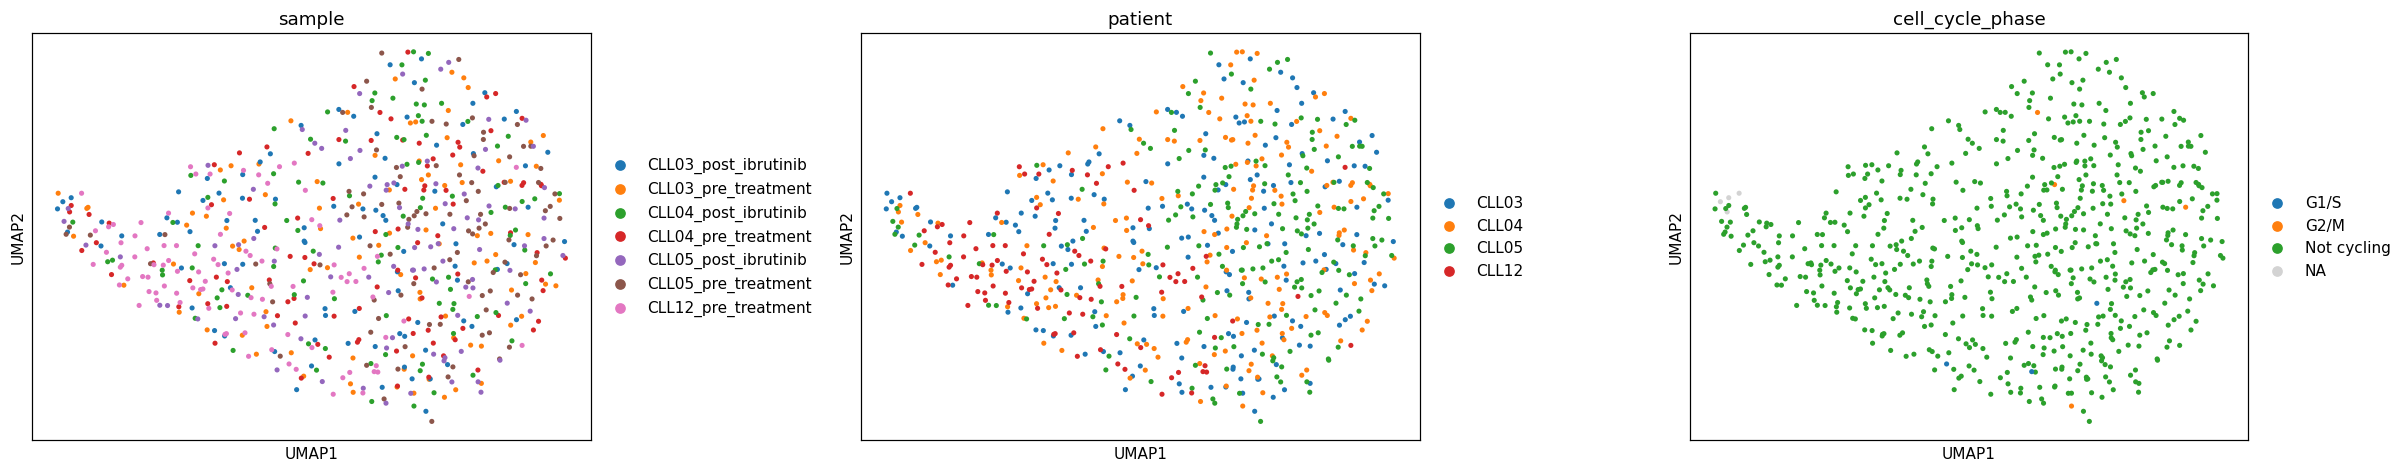

In [9]:
nsamp = adata.obs['sample'].nunique()
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median post-Harmony(theta=5) = {il_post:.2f} of {nsamp} samples '
      f'(pre-Harmony {il_pre:.2f}); 1 connected component, 0 islands removed')
sc.pl.umap(adata, color=['sample','patient','cell_cycle_phase'], size=45, wspace=.35)
print('Gate 1: 7 plates / 4 patients intermix per-neighbourhood on one continuous, low-cycling manifold -> PASS (GO)')

### Save processed data

In [10]:
protect = {'sample','lobe','celltype','cell_type','cell_cycle_phase','patient','sample_status','compartment'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    c = adata.obs[col]
    if c.dtype == object:
        conv = pd.to_numeric(c, errors='coerce')
        adata.obs[col] = conv if (c.notna().sum()>0 and conv.notna().sum()>=0.9*c.notna().sum()) else c.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (672, 36412)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 672


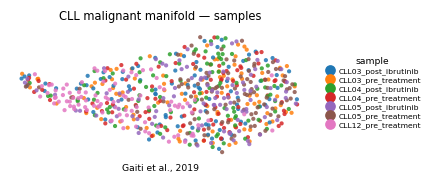

In [11]:
# House style: (3.5,1.5) horizontal strip, size=30, house orientation (X_umap_lin).
# Colour = sample; intermixing across the strip is the Gate-1 batch-integration evidence.
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.85, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('CLL malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Gaiti et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])